# Phase 3: Baseline and validation design

Run `python -m src.phase3` first. It saves the train/test split and the spatial folds to `data/processed/splits.parquet`, and every later phase reuses that file.

In [1]:
import os
import sys
sys.path.append('..')
os.environ['MLFLOW_DISABLE_AGENT_HINT'] = '1'

import geopandas as gpd
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from src.baseline import baselines, cross_validate
from src.config import DATA_PROCESSED
from src.plots import AQUA, BLUE, GRID, MUTED, ORANGE, save, use_style
from src.sources.geo import GEO_DIR
from src.validation import random_folds

use_style()
df = pd.read_parquet(DATA_PROCESSED / 'listings_features.parquet').merge(
    pd.read_parquet(DATA_PROCESSED / 'splits.parquet'), on='id')
train, test = df[~df['is_test']], df[df['is_test']]
len(train), len(test)

(3034, 758)

## 1. Time holdout
The newest 20% of listings are the test set. The test window is mostly the September 2019 burst, and it sits farther from downtown than the training data.

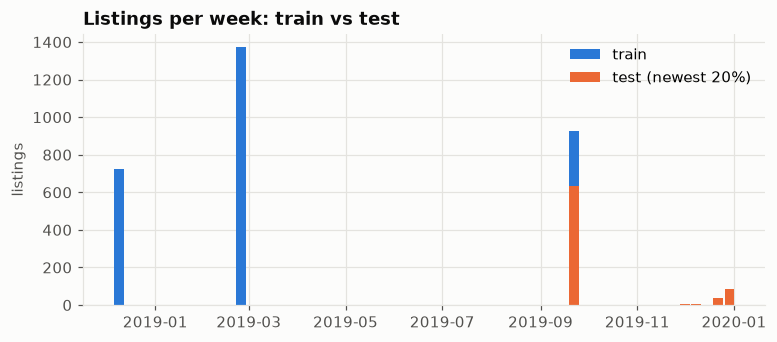

In [2]:
fig, ax = plt.subplots(figsize=(8, 3.2))
weekly = df.set_index('listed_at').groupby('is_test').resample('W')['id'].size().unstack(0).fillna(0)
ax.bar(weekly.index, weekly[False], width=6, color=BLUE, label='train')
ax.bar(weekly.index, weekly[True], width=6, color=ORANGE, label='test (newest 20%)')
ax.set_title('Listings per week: train vs test')
ax.set_ylabel('listings')
ax.legend()
save(fig, 'phase3_time_split')

## 2. Spatial folds
Each color is one fold. Every listing at a map point shares its cluster, and every listing in a cluster shares its fold.

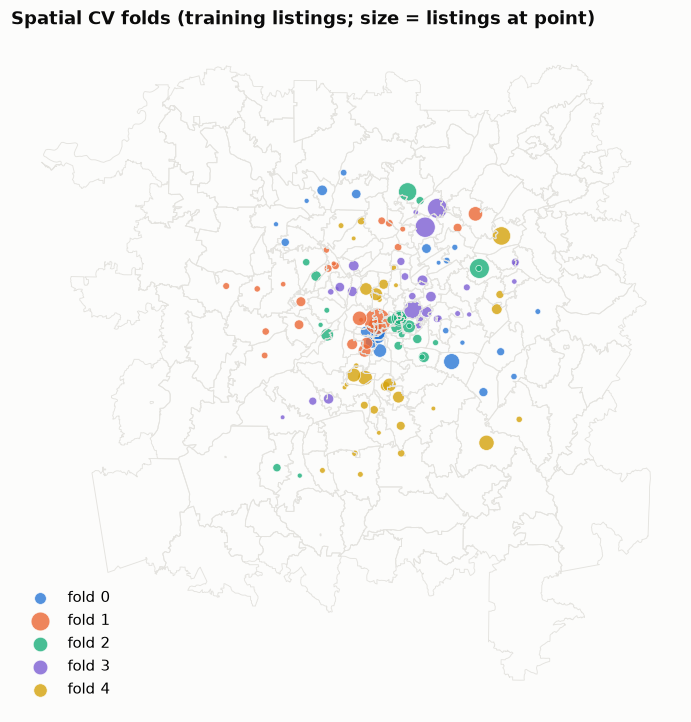

In [3]:
zcta = gpd.read_parquet(GEO_DIR / 'zcta_shapes.parquet')
pts = (train.groupby(['latitude', 'longitude'])
       .agg(n=('id', 'size'), fold=('fold', 'first'), cluster=('cluster', 'first')).reset_index())
colors = [BLUE, ORANGE, AQUA, '#7d5fd3', '#d4a20b']
fig, ax = plt.subplots(figsize=(8, 8))
zcta.boundary.plot(ax=ax, color=GRID, linewidth=0.6)
for f in sorted(pts['fold'].unique()):
    p = pts[pts['fold'] == f]
    ax.scatter(p['longitude'], p['latitude'], s=8 + p['n'] * 1.5, color=colors[f], alpha=0.8,
               edgecolor='white', linewidth=0.5, label=f'fold {f}')
ax.set_axis_off()
ax.set_title('Spatial CV folds (training listings; size = listings at point)')
ax.legend(loc='lower left')
save(fig, 'phase3_spatial_folds')

## 3. Random vs spatial CV
Random folds put listings from the same map point in both train and validation. The ZIP x beds median then gets to look up its own neighbors, and its error drops about \$90. Spatial CV removes that leak. Under spatial CV the ZIP baseline is no better than the bedroom median.

,baseline,cv,mae,sd
0,global_median,random,316.0,16.2
1,global_median,spatial,317.8,49.4
2,beds_median,random,305.2,14.7
3,beds_median,spatial,307.2,56.2
4,zip_beds_median,random,226.7,7.8
5,zip_beds_median,spatial,313.6,63.7


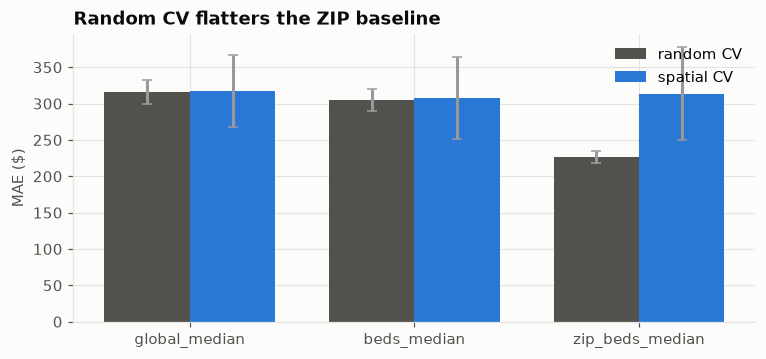

In [4]:
schemes = {'random': random_folds(train.index), 'spatial': train['fold']}
rows = []
for name, model in baselines().items():
    for scheme, folds in schemes.items():
        res = cross_validate(model, train, folds)
        rows.append({'baseline': name, 'cv': scheme, 'mae': res['mae'].mean(), 'sd': res['mae'].std()})
cv = pd.DataFrame(rows)

fig, ax = plt.subplots(figsize=(8, 3.4))
names = list(baselines())
x = np.arange(len(names))
for i, (scheme, color) in enumerate([('random', MUTED), ('spatial', BLUE)]):
    d = cv[cv['cv'] == scheme].set_index('baseline').loc[names]
    ax.bar(x + (i - 0.5) * 0.38, d['mae'], 0.38, yerr=d['sd'], color=color, label=f'{scheme} CV',
           error_kw={'ecolor': '#999', 'capsize': 3})
ax.set_xticks(x, names)
ax.set_ylabel('MAE ($)')
ax.set_title('Random CV flatters the ZIP baseline')
ax.legend()
save(fig, 'phase3_cv_comparison')
cv.round(1)

## 4. Test set errors (main baseline)

test MAE           221.7
median residual     -8.2
dtype: float64

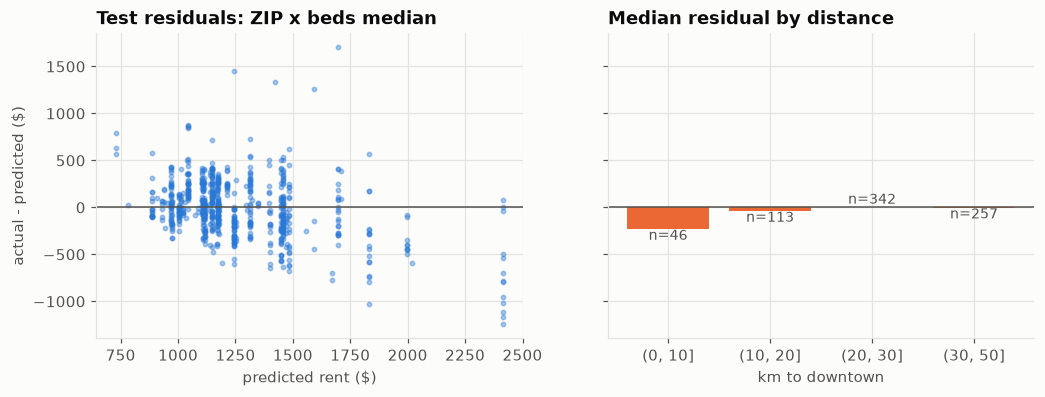

In [5]:
model = baselines()['zip_beds_median'].fit(train)
pred = test.join(model.predict_with_level(test))
pred['err'] = pred['rent'] - pred['pred']

fig, axes = plt.subplots(1, 2, figsize=(11, 3.6), sharey=True)
axes[0].scatter(pred['pred'], pred['err'], s=8, alpha=0.4, color=BLUE)
axes[0].axhline(0, color=MUTED, linewidth=1)
axes[0].set_xlabel('predicted rent ($)')
axes[0].set_ylabel('actual - predicted ($)')
axes[0].set_title('Test residuals: ZIP x beds median')
bins = pd.cut(pred['km_to_downtown'], [0, 10, 20, 30, 50])
med = pred.groupby(bins, observed=True)['err'].agg(['median', 'size'])
bars = axes[1].bar(med.index.astype(str), med['median'], color=ORANGE)
axes[1].bar_label(bars, labels=[f'n={n}' for n in med['size']], color=MUTED, fontsize=9)
axes[1].axhline(0, color=MUTED, linewidth=1)
axes[1].set_xlabel('km to downtown')
axes[1].set_title('Median residual by distance')
save(fig, 'phase3_test_residuals')
pd.Series({'test MAE': pred['err'].abs().mean(), 'median residual': pred['err'].median()}).round(1)

## 5. Summary

- **Split.** Train: 3,034 listings (Dec 2018 to Sep 18, 2019). Test: 758 listings (Sep 18 to Dec 2019). The test window is more suburban (median 28 km from downtown vs 15 km) and cheaper (\$1,195 vs \$1,340 median), so it is a shifted sample, not a random one.
- **Spatial CV.** 40 KMeans clusters dealt into 5 equal folds. No cluster or map point is in both train and validation (tested). An earlier 20-cluster version put all of downtown in one fold. Its folds were a city fold plus suburban folds, and fold error swung from \$236 to \$503. 40 clusters halved that spread.
- **Leakage is real.** Random CV says the ZIP x beds baseline has MAE \$227. Spatial CV says \$314. Same-point near-copies inflate random CV. Under spatial CV the ZIP lookup hits only 6% of the time, so the baseline is effectively the bedroom median.
- **Baseline to beat (test).** ZIP x beds median: **MAE \$222** (95% CI \$208-\$238), MAPE 18.2%. Phase 4 target: **MAE <= \$177**.
- **Where it misses.** In-town test listings (< 10 km) came in about \$230 below their ZIP medians (n = 46). Suburban listings are nearly unbiased. Only 46 listings, but worth watching in Phase 4.